In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

import generate_behavdf as gm
# from preproc_funcs import *
# from generate_plots import *
# from helpers import *
# from preproc_funcs import *
from scipy import stats
import plotly.graph_objects as go
from statsmodels.stats.anova import AnovaRM
import pingouin as pg

pd.set_option("display.max.columns", None)
pd.set_option("display.precision", 4)

msize = 10
axes_fontsize = 14
title_fontsize = 18
%load_ext autoreload
%autoreload 2

Creating a new dataframe...
We have 1 subjects so far: [0]



In [4]:
df = gm.master_df
oriArrayCols = [col for col in df.columns if col.startswith('oriArray_')]
df['oriSteps'] = df[oriArrayCols].notna().sum(axis=1)

In [5]:
df.head()

,subjID,day,block,TMScond,stimPF,targOriCategory,targOriActual,stimSize,targX,targY,rho,polang,initDuration,sampleDuration,delay1Duration,delay2Duration,respDuration,feedbackDuration,itiDuration,trialDuration,initOri,oriArray_1,oriArray_2,oriArray_3,oriArray_4,oriArray_5,oriArray_6,oriArray_7,oriArray_8,oriArray_9,oriArray_10,oriArray_11,oriArray_12,oriArray_13,oriArray_14,oriArray_15,oriArray_16,oriArray_17,oriArray_18,oriArray_19,oriArray_20,oriArray_21,oriArray_22,oriArray_23,oriArray_24,oriArray_25,oriArray_26,oriArray_27,oriArray_28,oriArray_29,oriArray_30,oriArray_31,oriArray_32,oriArray_33,oriArray_34,oriArray_35,oriArray_36,oriArray_37,oriArray_38,oriArray_39,oriArray_40,oriArray_41,oriArray_42,oriArray_43,oriArray_44,oriArray_45,oriArray_46,oriArray_47,oriArray_48,oriArray_49,oriArray_50,oriArray_51,oriArray_52,oriArray_53,oriArray_54,oriArray_55,oriArray_56,oriArray_57,oriArray_58,oriArray_59,oriArray_60,oriArray_61,oriArray_62,oriArray_63,oriArray_64,oriArray_65,oriArray_66,oriArray_67,oriArray_68,oriArray_69,oriArray_70,oriArray_71,oriArray_72,oriArray_73,oriArray_74,oriArray_75,oriArray_76,oriArray_77,oriArray_78,oriArray_79,oriArray_80,oriArray_81,oriArray_82,oriArray_83,oriArray_84,oriArray_85,oriArray_86,oriArray_87,oriArray_88,oriArray_89,oriArray_90,oriArray_91,oriArray_92,oriArray_93,oriArray_94,oriArray_95,oriArray_96,oriArray_97,oriArray_98,oriArray_99,oriArray_100,oriArray_101,oriArray_102,oriArray_103,oriArray_104,oriArray_105,oriArray_106,oriArray_107,oriArray_108,oriArray_109,oriArray_110,oriArray_111,oriArray_112,oriArray_113,oriArray_114,oriArray_115,oriArray_116,oriArray_117,oriArray_118,oriArray_119,oriArray_120,oriArray_121,oriArray_122,oriArray_123,oriArray_124,oriArray_125,oriArray_126,oriArray_127,oriArray_128,oriArray_129,oriArray_130,oriArray_131,oriArray_132,oriArray_133,oriArray_134,oriArray_135,oriArray_136,oriArray_137,oriArray_138,oriArray_139,oriArray_140,oriArray_141,oriArray_142,oriArray_143,oriArray_144,oriArray_145,oriArray_146,oriArray_147,oriArray_148,oriArray_149,oriArray_150,oriArray_151,oriArray_152,oriArray_153,oriArray_154,oriArray_155,oriArray_156,oriArray_157,oriArray_158,oriArray_159,oriArray_160,oriArray_161,oriArray_162,oriArray_163,oriArray_164,oriArray_165,oriArray_166,oriArray_167,oriArray_168,oriArray_169,oriArray_170,oriArray_171,oriArray_172,oriArray_173,oriArray_174,oriArray_175,oriArray_176,oriArray_177,oriArray_178,finalOri,RT,errorOri,oriSteps
0,0,1,1,3,1,150,150.4502,165,655.9717,874.0395,524.2877,152.2594,1.0004,0.2505,2.0005,2.0005,1.2595,1.0005,2.5005,9.0136,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,117.9176,118.9176,119.9176,120.9176,121.9176,122.9176,123.9176,124.9176,125.9176,126.9176,126.9176,127.9176,128.9176,128.9176,129.9176,129.9176,129.9176,129.9176,129.9176,129.9176,129.9176,129.9176,129.9176,130.9176,130.9176,131.9176,132.9176,133.9176,133.9176,134.9176,135.9176,135.9176,136.9176,137.9176,137.9176,137.9176,137.9176,137.9176,138.9176,140.9176,140.9176,141.9176,141.9176,143.9176,144.9176,145.9176,145.9176,147.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,148.9176,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,148.9176,1.2532,1.5326,116
1,0,1,1,3,1,150,141.0927,165,655.9717,874.0395,524.2877,152.2594,1.0006,0.2503,2.0005,2.0004,2.007

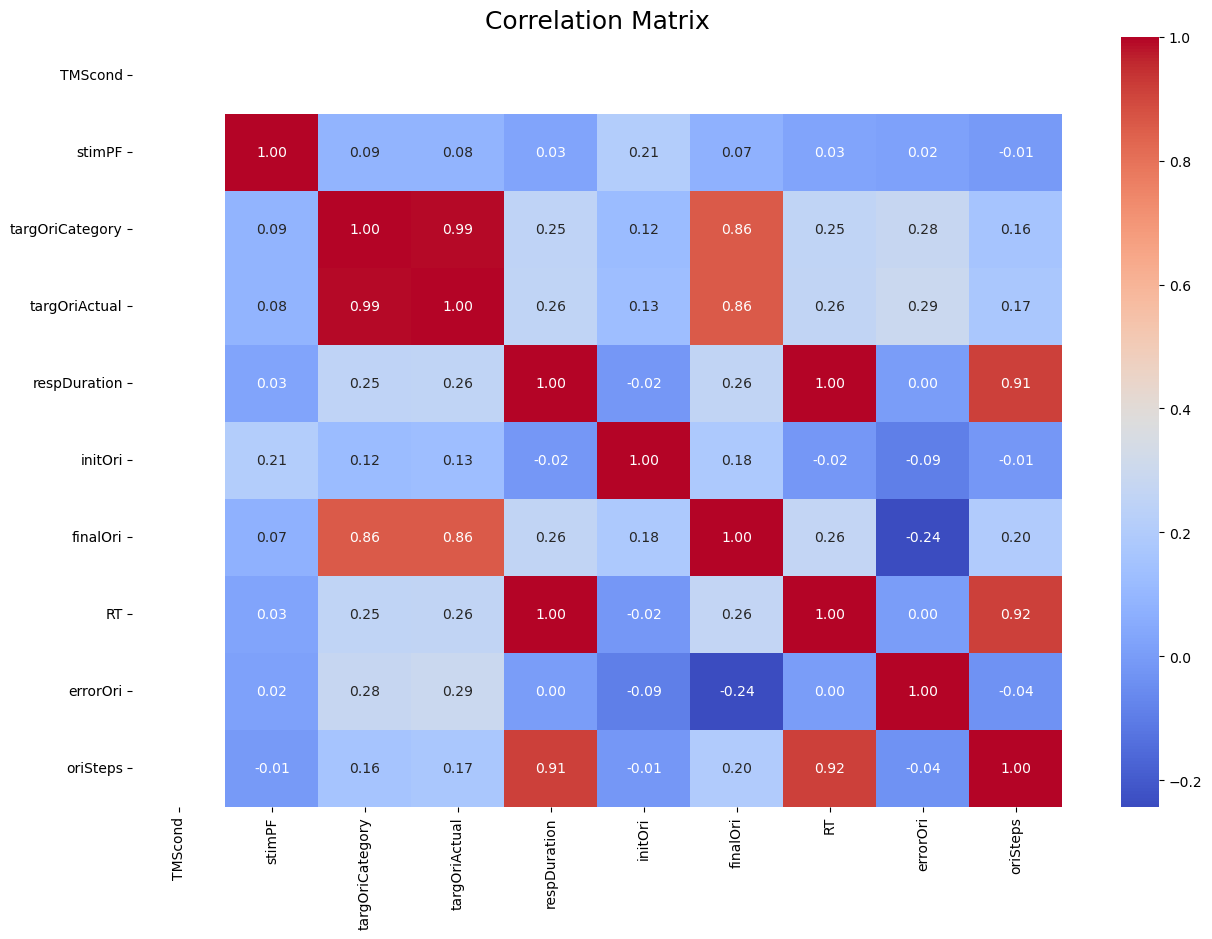

In [6]:
exploratory_cols = ['TMScond', 'stimPF', 'targOriCategory', 'targOriActual', 'respDuration', 'initOri', 'finalOri', 'RT', 'errorOri', 'oriSteps']
plt.figure(figsize=(15, 10))
sns.heatmap(df[exploratory_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix', fontsize=title_fontsize)
plt.show()

<Figure size 1500x1000 with 0 Axes>

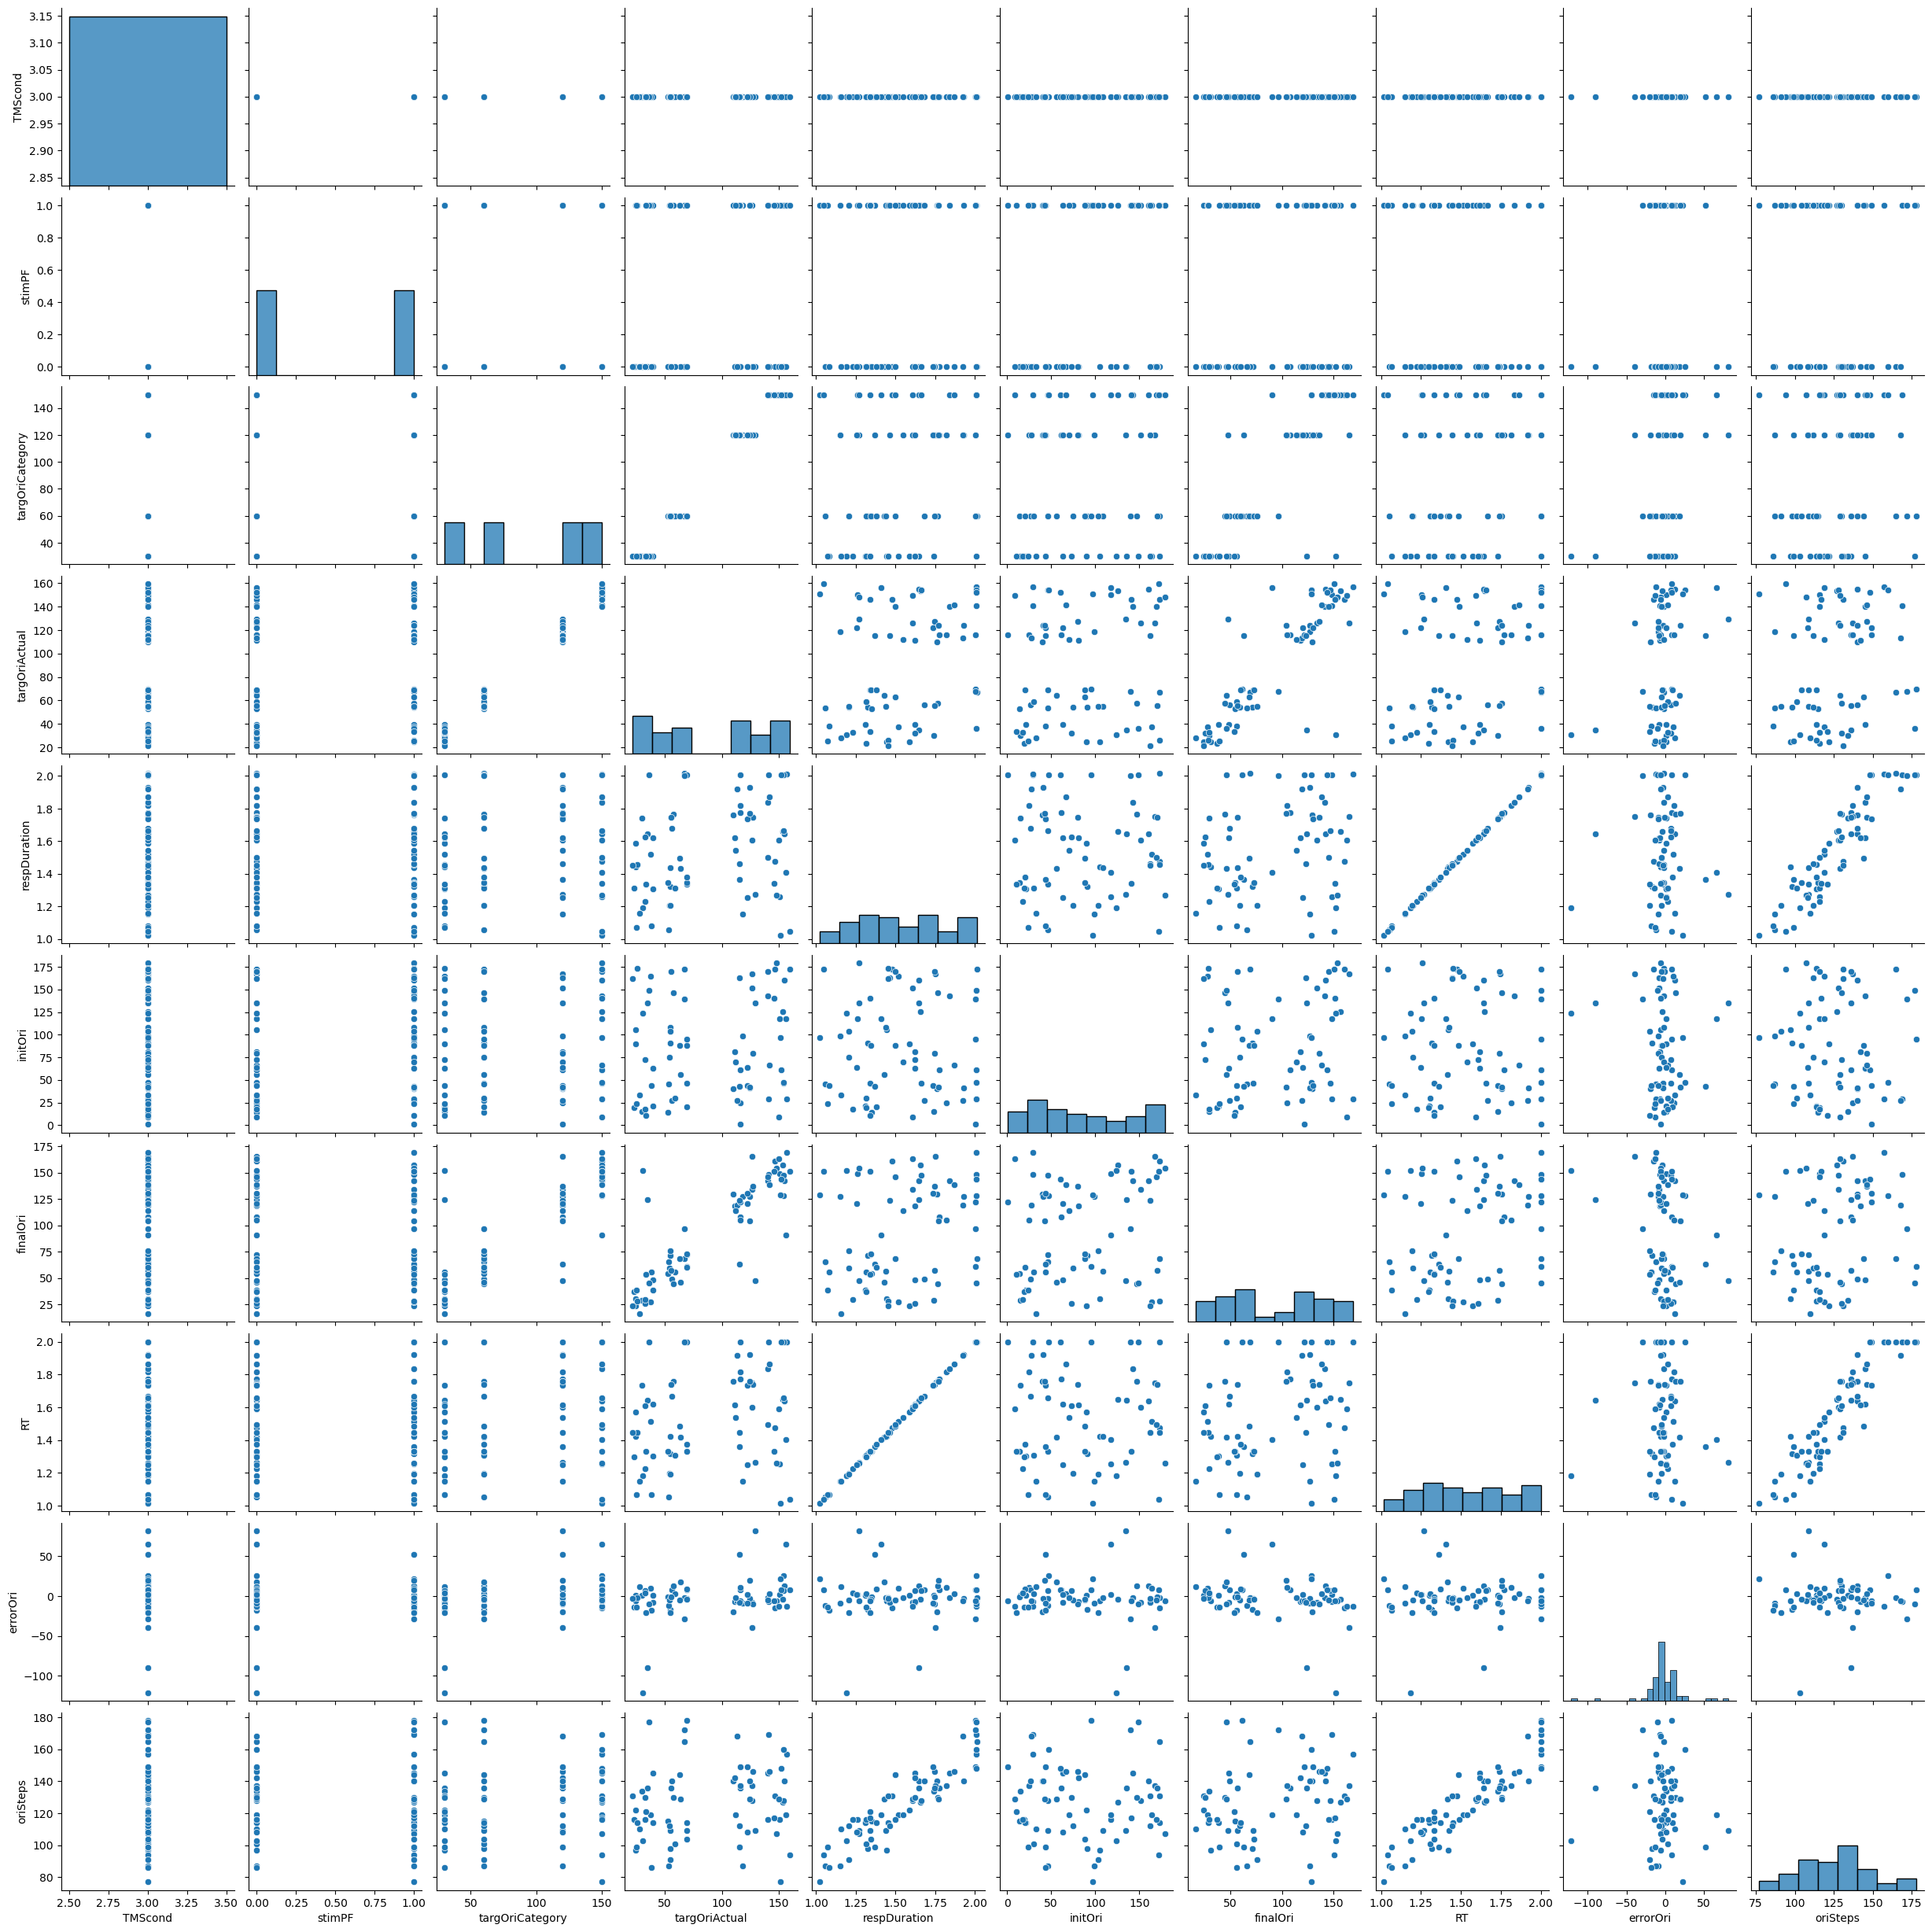

In [7]:
plt.figure(figsize=(15, 10))
sns.pairplot(df[exploratory_cols])
plt.show()